# 01 — Dataset Overview

**Dataset:** NASA DASHlink *Curated 4 Class Anomaly Detection Data Set*: 160-second windows
of 20 flight variables recorded as aircraft cross ~1,000 ft on final approach.

**Goal:** understand class balance, where the data comes from (aircraft, years, airports), and how
each class behaves over the window, before any modelling.

Data is read from the float32 working copy (`python -m flightops.data.processed`). See
`docs/dataset-card.md` for provenance and `docs/data-dictionary.md` for variable definitions.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flightops.config import load_data_config, project_root
from flightops.data.processed import load_processed
from flightops.data.quality import parse_flight_record
from flightops.data.schema import FEATURES, FEATURE_NAMES, IDX, LABELS

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = project_root() / "artifacts" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_COLORS = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868", 3: "#c44e52"}

cfg = load_data_config()
X, y = load_processed()          # X is memory-mapped float32: (windows, seconds, variables)
meta = pd.read_csv(cfg.metadata_path, dtype={"flight_record": str})
meta = meta.join(parse_flight_record(meta["flight_record"]))
assert len(meta) == len(y) and (meta["label"].to_numpy() == y).all()
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)


X: (99837, 160, 20) float32 | y: (99837,) int8


## 1. Class balance

,class,count,share_%
0,Nominal,89663,89.81
1,Speed High,7013,7.02
2,Path High,2207,2.21
3,Flaps Late Setting,954,0.96


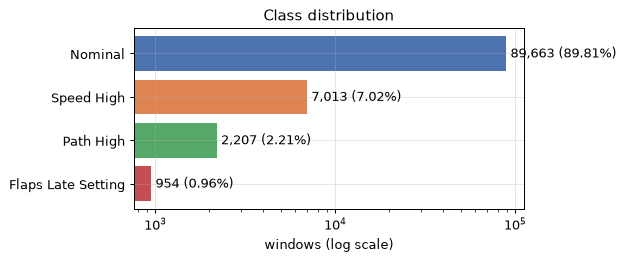

In [2]:
counts = pd.Series(y).value_counts().sort_index()
dist = pd.DataFrame({"class": [LABELS[k] for k in counts.index], "count": counts.values,
                     "share_%": (counts / counts.sum() * 100).round(2).values}, index=counts.index)
display(dist)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(dist["class"], dist["count"], color=[CLASS_COLORS[k] for k in dist.index])
for i, (c, s) in enumerate(zip(dist["count"], dist["share_%"])):
    ax.text(c, i, f" {c:,} ({s}%)", va="center")
ax.set_xscale("log"); ax.set_xlabel("windows (log scale)"); ax.invert_yaxis(); ax.set_title("Class distribution")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_class_distribution.png")

About 90% of windows are nominal and the smallest class (Flaps Late) is under 1%. Accuracy would
be misleading, so evaluation must use per-class precision and recall and PR-AUC (documentation.md §14).

## 2. Aircraft and time coverage

`flight_record` is parsed as *3-digit aircraft id + YYYYMMDDHHMM*. This layout is inferred and undocumented, but all records match it.

aircraft: 35
record years: {1998: 6, 2001: 27245, 2002: 36675, 2003: 26571, 2004: 8207, 2009: 343, 2010: 790}


,count,mean,std,min,25%,50%,75%,max
windows,35.0,2852.486,331.922,2236.000,2609.500,2828.000,3132.000,3474.00
anomaly_rate,35.0,0.104,0.137,0.067,0.074,0.083,0.088,0.89


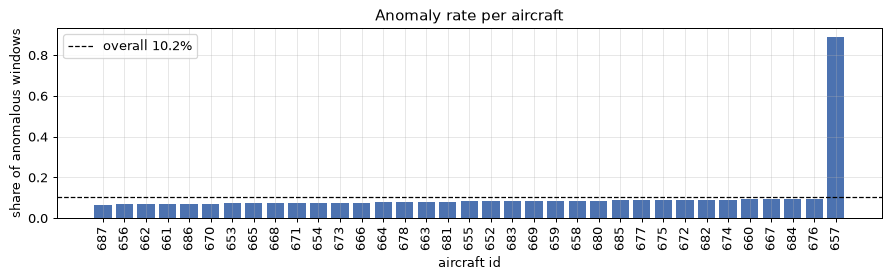

In [3]:
print("aircraft:", meta["aircraft_id"].nunique())
print("record years:", meta["record_time"].dt.year.value_counts().sort_index().to_dict())

per_ac = meta.groupby("aircraft_id").agg(windows=("label", "size"), anomaly_rate=("label", lambda s: (s > 0).mean()))
per_ac = per_ac.sort_values("anomaly_rate")
display(per_ac.describe().round(3).T)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(per_ac.index, per_ac["anomaly_rate"], color="#4c72b0")
ax.axhline((y > 0).mean(), color="k", ls="--", lw=1, label=f"overall {(y > 0).mean():.1%}")
ax.set_ylabel("share of anomalous windows"); ax.set_xlabel("aircraft id"); ax.legend()
ax.set_title("Anomaly rate per aircraft"); plt.setp(ax.get_xticklabels(), rotation=90)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_anomaly_rate_per_aircraft.png")

In [4]:
outlier = per_ac["anomaly_rate"].idxmax()
print(f"Aircraft {outlier}: {per_ac.loc[outlier, 'windows']} windows")
display(pd.crosstab(meta.loc[meta.aircraft_id == outlier, "label"].map(LABELS), "count"))

Aircraft 657: 2527 windows


col_0,count
label,
Flaps Late Setting,4
Nominal,279
Path High,7
Speed High,2237


**Finding:** anomaly rates are similar across aircraft (median ≈8%) except one, aircraft 657. It is
mostly *Speed High* and accounts for about a third of all Speed High labels. A model could learn to
recognise this aircraft instead of the speed problem itself, so Phase 2 must include an
**aircraft-held-out** evaluation alongside the stratified split.

## 3. Airports

In [5]:
ap = meta.groupby("arrival_airport").agg(windows=("label", "size"), anomaly_rate=("label", lambda s: (s > 0).mean()))
print("departure airports:", meta["departure_airport"].nunique(), "| arrival airports:", meta["arrival_airport"].nunique())
display(ap.sort_values("windows", ascending=False).head(15).round(3))

departure airports: 205 | arrival airports: 97


,windows,anomaly_rate
arrival_airport,,
KMSP,25396,0.064
KDTW,18797,0.094
KMEM,9557,0.124
KOKC,2544,0.126
KDSM,2367,0.116
KCVG,2162,0.171
KPIT,1600,0.108
KSTL,1487,0.130
KOMA,1462,0.070


## 4. How each class behaves over the window

Median (line) and interquartile range (band) per second, using up to 3,000 random windows per class.
Altitude is shown relative to the last second of the window, because raw altitude is barometric (MSL)
and depends on airport elevation (see notebook 02).

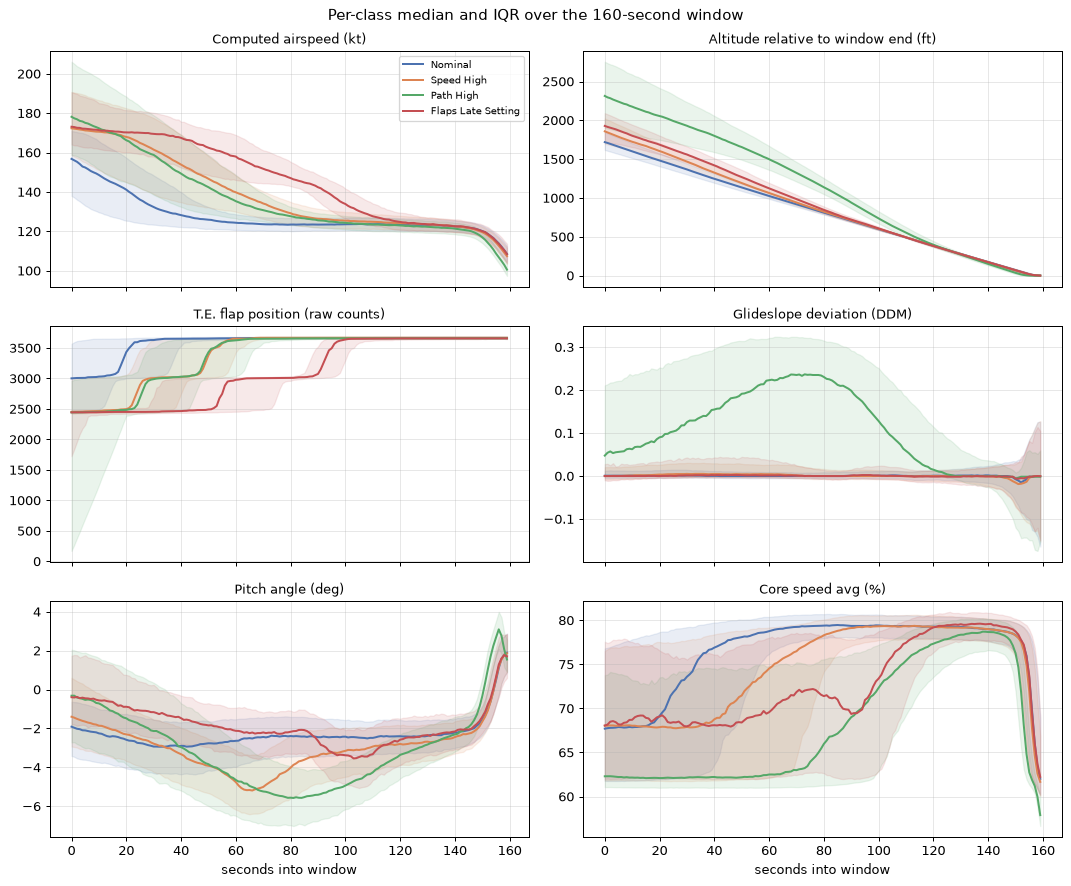

In [6]:
rng = np.random.default_rng(42)
sample_idx = {k: np.sort(rng.choice(np.where(y == k)[0], size=min(3000, (y == k).sum()), replace=False)) for k in LABELS}
t = np.arange(X.shape[1])

def series(idx, name):
    a = np.asarray(X[idx][:, :, IDX[name]], dtype=np.float64)
    return a - a[:, -1:] if name == "altitude" else a

panels = [("airspeed", "Computed airspeed (kt)"), ("altitude", "Altitude relative to window end (ft)"),
          ("flap", "T.E. flap position (raw counts)"), ("glideslope_dev", "Glideslope deviation (DDM)"),
          ("pitch", "Pitch angle (deg)"), ("core_speed", "Core speed avg (%)")]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for ax, (name, title) in zip(axes.ravel(), panels):
    for k, idx in sample_idx.items():
        s = series(idx, name)
        q25, q50, q75 = np.percentile(s, [25, 50, 75], axis=0)
        ax.plot(t, q50, color=CLASS_COLORS[k], label=LABELS[k], lw=1.6)
        ax.fill_between(t, q25, q75, color=CLASS_COLORS[k], alpha=0.12)
    ax.set_title(title, fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("seconds into window")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Per-class median and IQR over the 160-second window"); fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_trajectories.png")

In [7]:
# Window-level summary per class (median of per-window statistic)
def window_stat(name, fn):
    return pd.Series({LABELS[k]: float(np.median(fn(series(idx, name)))) for k, idx in sample_idx.items()})

summary = pd.DataFrame({
    "airspeed_end_kt": window_stat("airspeed", lambda a: a[:, -1]),
    "airspeed_max_kt": window_stat("airspeed", lambda a: a.max(1)),
    "glideslope_dev_mean": window_stat("glideslope_dev", lambda a: a.mean(1)),
    "flap_start": window_stat("flap", lambda a: a[:, 0]),
    "first_sec_flap_ge_3600": window_stat("flap", lambda a: np.where((a >= 3600).any(1), (a >= 3600).argmax(1), 160)),
    "altitude_drop_ft": window_stat("altitude", lambda a: a[:, 0]),
})
display(summary.round(3))

,airspeed_end_kt,airspeed_max_kt,glideslope_dev_mean,flap_start,first_sec_flap_ge_3600,altitude_drop_ft
Nominal,108.517,157.343,0.001,3002.0,25.0,1718.915
Speed High,107.367,175.132,0.002,2452.0,56.0,1858.102
Path High,100.536,179.545,0.120,2443.0,57.0,2314.132
Flaps Late Setting,108.398,176.372,0.001,2444.0,97.0,1927.839


**Observations**

- The window ends at touchdown: airspeed drops, pitch flares, and throttle (core speed) is cut in the
  last ~10 s. It starts roughly 1,700–2,300 ft above the end point.
- Each anomaly class matches its name:
  - **Flaps Late** reaches the final flap setting much later than nominal (median second ~97 vs ~25).
  - **Path High** sits clearly above the glideslope for the first ~100 s and descends more steeply.
  - **Speed High** has higher peak airspeed and a later reduction to approach speed.
- All three anomaly classes start with flaps at an intermediate setting (~2,450 counts), while nominal
  starts at ~3,000. They also carry more airspeed early, which suggests the classes overlap (an
  unstable approach often shows several symptoms).
- Simple window features separate the classes well. A supervised classifier is a useful upper-bound
  reference, but the project's main goal is to detect these classes **without** labels, by modelling
  nominal behaviour.

## 5. Example windows (one random window per class)

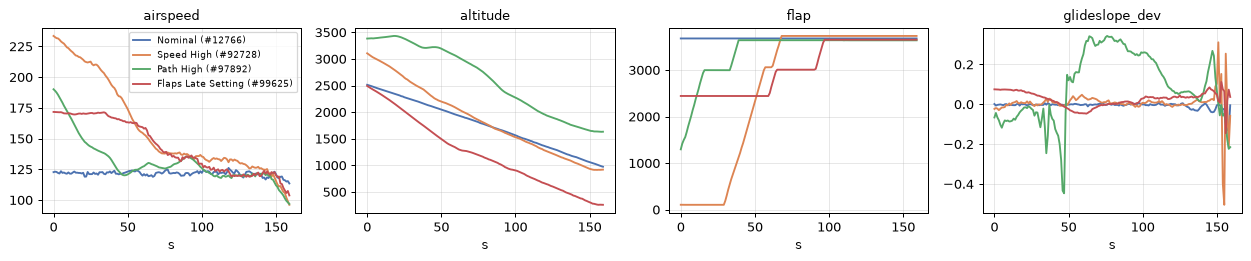

In [8]:
ex = {k: int(rng.choice(np.where(y == k)[0])) for k in LABELS}
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True)
for ax, name in zip(axes, ["airspeed", "altitude", "flap", "glideslope_dev"]):
    for k, i in ex.items():
        ax.plot(t, X[i, :, IDX[name]], color=CLASS_COLORS[k], label=f"{LABELS[k]} (#{i})")
    ax.set_title(name, fontsize=10); ax.set_xlabel("s")
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG_DIR / "01_example_windows.png")